# AI Health Risk Predictor — Data Science & Machine Learning Analysis

**Educational risk-assessment project. Not a medical diagnostic tool.**

This notebook covers the complete data science workflow for two diseases:
1. Diabetes Risk
2. Heart Disease Risk

Sections: Data Loading → Cleaning → EDA → Feature Analysis → Preprocessing →
Model Training → Model Comparison → Evaluation → Feature Importance → Model Saving

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries loaded successfully")

Libraries loaded successfully


## 1. Diabetes Dataset — Loading

In [11]:
diabetes_df = pd.read_csv("../data/diabetes.csv")

print("Shape:", diabetes_df.shape)
diabetes_df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
diabetes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [13]:
diabetes_df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 2. Diabetes Dataset — Cleaning

**Why this matters (data leakage / data quality awareness):**

Five columns — `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` —
contain zero values that are not biologically plausible. These almost certainly
represent missing measurements that were encoded as 0 rather than left blank
when this dataset was originally compiled.

If left as-is, a value of 0 in `BMI` or `Glucose` would mislead the model into
learning a false pattern ("BMI of 0 correlates with X"), rather than reflecting
a real physiological relationship. We treat these zeros as missing values and
impute them using the **median** of each column (median is preferred over mean
here because these features are not perfectly symmetric/normal — median is more
robust to outliers).

We do **not** touch `Pregnancies` (0 is a valid, common value) or `Outcome`
(the target column).

In [14]:
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Count of zero values per column (treated as missing):\n")
for col in zero_as_missing_cols:
    zero_count = (diabetes_df[col] == 0).sum()
    pct = round((zero_count / len(diabetes_df)) * 100, 1)
    print(f"{col}: {zero_count} zeros ({pct}%)")

Count of zero values per column (treated as missing):

Glucose: 5 zeros (0.7%)
BloodPressure: 35 zeros (4.6%)
SkinThickness: 227 zeros (29.6%)
Insulin: 374 zeros (48.7%)
BMI: 11 zeros (1.4%)


In [15]:
diabetes_clean = diabetes_df.copy()

# Step 1: convert the fake zeros into real, explicit missing values
diabetes_clean[zero_as_missing_cols] = diabetes_clean[zero_as_missing_cols].replace(0, np.nan)

print("Missing values after converting zeros to NaN:\n")
print(diabetes_clean.isnull().sum())

Missing values after converting zeros to NaN:

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [16]:
for col in zero_as_missing_cols:
    median_value = diabetes_clean[col].median()
    diabetes_clean[col] = diabetes_clean[col].fillna(median_value)
    print(f"{col}: filled missing values with median = {median_value}")

print("\nRemaining missing values:", diabetes_clean.isnull().sum().sum())

Glucose: filled missing values with median = 117.0
BloodPressure: filled missing values with median = 72.0
SkinThickness: filled missing values with median = 29.0
Insulin: filled missing values with median = 125.0
BMI: filled missing values with median = 32.3

Remaining missing values: 0


In [17]:
duplicate_count = diabetes_clean.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    diabetes_clean = diabetes_clean.drop_duplicates()
    print(f"Duplicates removed. New shape: {diabetes_clean.shape}")
else:
    print("No duplicate rows found.")

Duplicate rows: 0
No duplicate rows found.


In [18]:
print("Diabetes dataset cleaned successfully.")
print("Final shape:", diabetes_clean.shape)
diabetes_clean.head()

Diabetes dataset cleaned successfully.
Final shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 3. Diabetes Dataset — Exploratory Data Analysis (EDA)

This section visualizes the cleaned dataset to understand feature distributions,
class balance, and relationships between variables before model training.

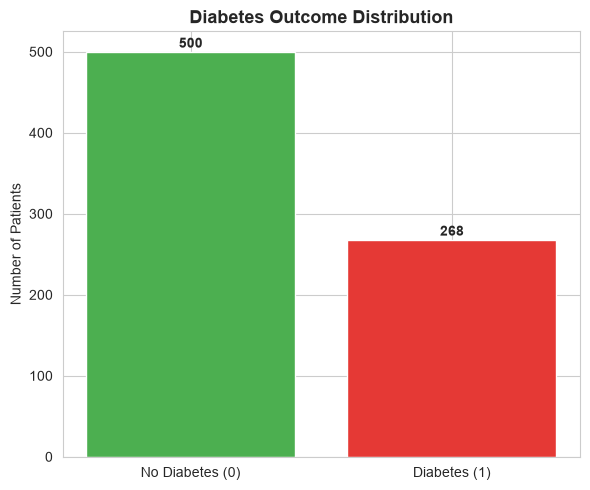

Class balance:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64 %


In [19]:
plt.figure(figsize=(6, 5))
outcome_counts = diabetes_clean["Outcome"].value_counts()
colors = ["#4CAF50", "#E53935"]

plt.bar(["No Diabetes (0)", "Diabetes (1)"], outcome_counts.values, color=colors)
plt.title("Diabetes Outcome Distribution", fontsize=13, fontweight="bold")
plt.ylabel("Number of Patients")

for i, count in enumerate(outcome_counts.values):
    plt.text(i, count + 5, str(count), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("Class balance:")
print(diabetes_clean["Outcome"].value_counts(normalize=True).round(3) * 100, "%")


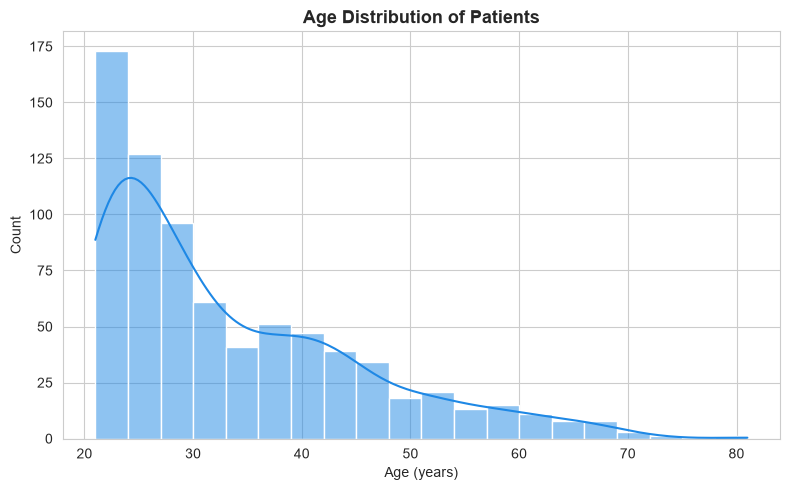

Age summary:
count    768.0
mean      33.2
std       11.8
min       21.0
25%       24.0
50%       29.0
75%       41.0
max       81.0
Name: Age, dtype: float64


In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(diabetes_clean["Age"], bins=20, kde=True, color="#1E88E5")
plt.title("Age Distribution of Patients", fontsize=13, fontweight="bold")
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Age summary:")
print(diabetes_clean["Age"].describe().round(1))

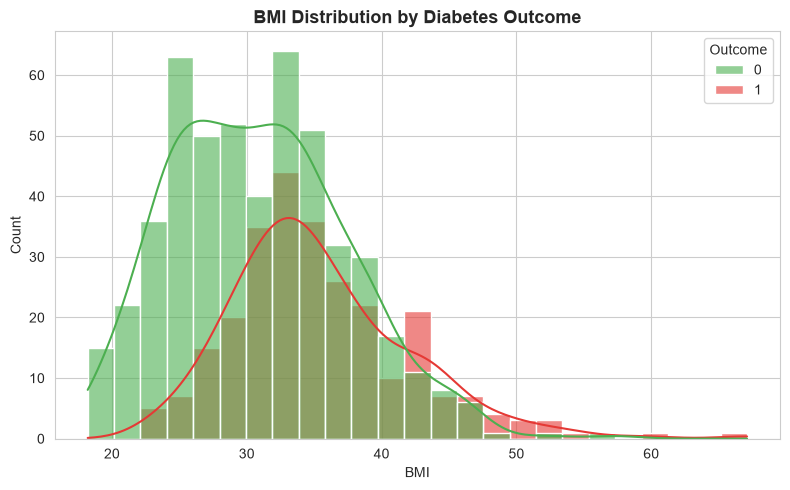

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(data=diabetes_clean, x="BMI", hue="Outcome", bins=25, kde=True,
             palette=["#4CAF50", "#E53935"], alpha=0.6)
plt.title("BMI Distribution by Diabetes Outcome", fontsize=13, fontweight="bold")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

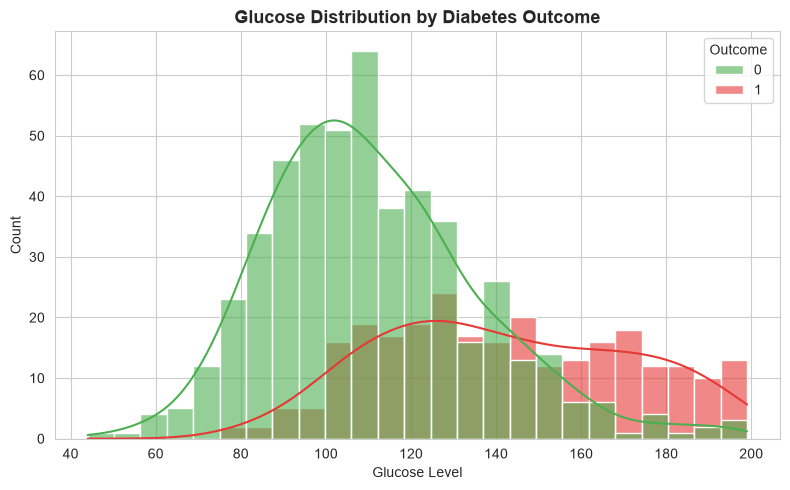

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(data=diabetes_clean, x="Glucose", hue="Outcome", bins=25, kde=True,
             palette=["#4CAF50", "#E53935"], alpha=0.6)
plt.title("Glucose Distribution by Diabetes Outcome", fontsize=13, fontweight="bold")
plt.xlabel("Glucose Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

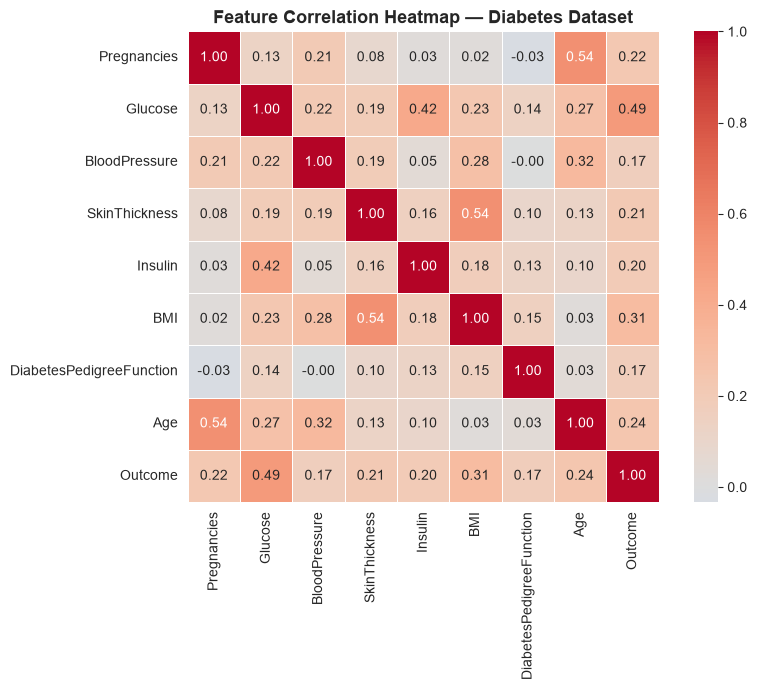

Correlation of each feature with Outcome (sorted):
Outcome                     1.000
Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64


In [23]:
plt.figure(figsize=(9, 7))
correlation_matrix = diabetes_clean.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True)
plt.title("Feature Correlation Heatmap — Diabetes Dataset", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Correlation of each feature with Outcome (sorted):")
print(correlation_matrix["Outcome"].sort_values(ascending=False).round(3))

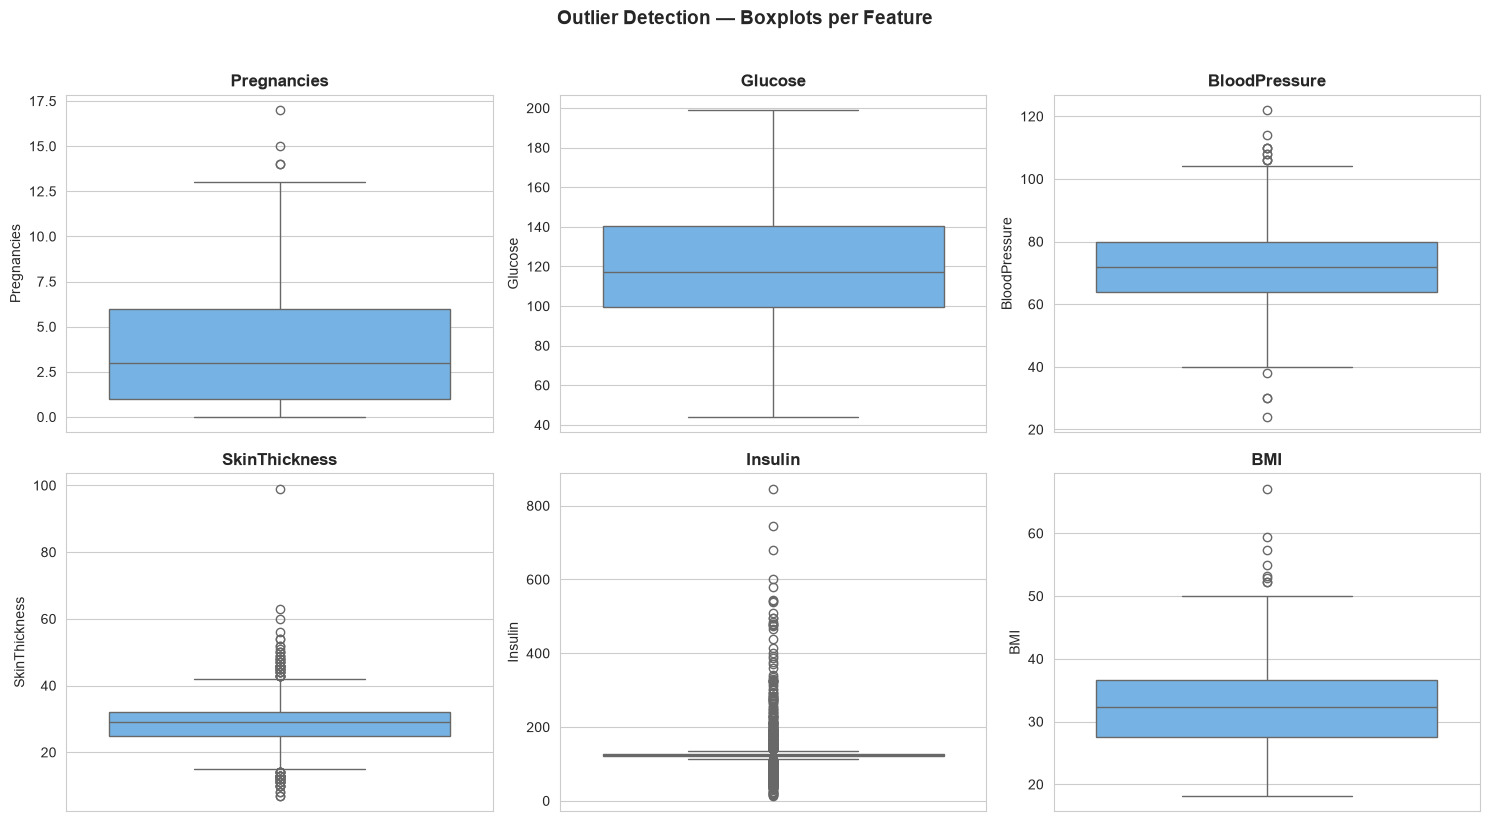

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
numeric_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for idx, col in enumerate(numeric_cols):
    row, colpos = idx // 3, idx % 3
    sns.boxplot(y=diabetes_clean[col], ax=axes[row, colpos], color="#64B5F6")
    axes[row, colpos].set_title(col, fontweight="bold")

plt.suptitle("Outlier Detection — Boxplots per Feature", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### EDA Summary — Diabetes

- Dataset shows class imbalance (~65% No Diabetes, ~35% Diabetes) — noted for
  model evaluation strategy later.
- Glucose shows the strongest visual and correlational relationship with Outcome.
- BMI and Age also show meaningful separation between classes.
- Outliers exist in Insulin and SkinThickness but are retained, as they likely
  represent genuine clinical extremes rather than data entry errors.

## 4. Heart Disease Dataset — Loading

In [25]:
heart_df = pd.read_csv("../data/heart.csv")

print("Shape:", heart_df.shape)
heart_df.head()

Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [26]:
heart_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [27]:
heart_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


### Column Reference — Heart Disease Dataset

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (0–3; 0 = typical angina ... 3 = asymptomatic) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| restecg | Resting ECG results (0–2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment (0–2) |
| ca | Number of major vessels colored by fluoroscopy (0–4) |
| thal | Thalassemia result (categorical code) |
| target | 1 = heart disease present, 0 = absent |

**Note:** Unlike the Diabetes dataset, this dataset does not use 0 as a
placeholder for missing data in its numeric columns (0 is a genuinely valid
value for columns like `exang`, `fbs`, `sex`, etc., since these are categorical
flags). We will check for actual missing values (NaN) and duplicates instead
of the zero-substitution issue we handled for Diabetes.

In [29]:
print("Missing values per column:\n")
print(heart_df.isnull().sum())
print("\nTotal missing values:", heart_df.isnull().sum().sum())

Missing values per column:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0


In [37]:
duplicate_count = heart_df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

heart_clean = heart_df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {heart_clean.shape}")

Duplicate rows: 723
Shape after removing duplicates: (302, 14)


In [36]:
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

for col in categorical_cols:
    print(f"{col}: unique values = {sorted(heart_clean[col].unique())}")   

sex: unique values = [np.int64(0), np.int64(1)]
cp: unique values = [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fbs: unique values = [np.int64(0), np.int64(1)]
restecg: unique values = [np.int64(0), np.int64(1), np.int64(2)]
exang: unique values = [np.int64(0), np.int64(1)]
slope: unique values = [np.int64(0), np.int64(1), np.int64(2)]
ca: unique values = [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal: unique values = [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


### Duplicate Investigation — Heart Disease Dataset

The dataset as downloaded contains 1025 rows, but 723 of these are exact
duplicate records, leaving only 302 unique patient records.

This is a known characteristic of this particular Kaggle upload: the
underlying data originates from the much smaller (~303-row) UCI Cleveland
Heart Disease dataset, which appears to have been duplicated multiple times
when this version was compiled.

**Why this matters:** training on the un-deduplicated data would risk data
leakage — identical rows could appear in both the training and test splits
after a random split, artificially inflating evaluation metrics without the
model learning any genuine pattern. All Heart Disease modeling in this
project therefore uses the deduplicated `heart_clean` dataset (302 rows).

All categorical columns (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`,
`ca`, `thal`) were checked and contain only valid, expected value ranges —
no further cleaning required for these.

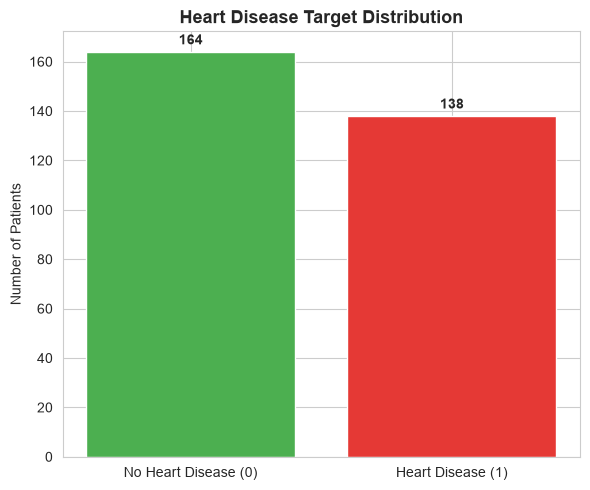

Class balance:
target
1    54.3
0    45.7
Name: proportion, dtype: float64 %


In [38]:
plt.figure(figsize=(6, 5))
target_counts = heart_clean["target"].value_counts()
colors = ["#4CAF50", "#E53935"]

plt.bar(["No Heart Disease (0)", "Heart Disease (1)"], target_counts.values, color=colors)
plt.title("Heart Disease Target Distribution", fontsize=13, fontweight="bold")
plt.ylabel("Number of Patients")

for i, count in enumerate(target_counts.values):
    plt.text(i, count + 3, str(count), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("Class balance:")
print(heart_clean["target"].value_counts(normalize=True).round(3) * 100, "%")

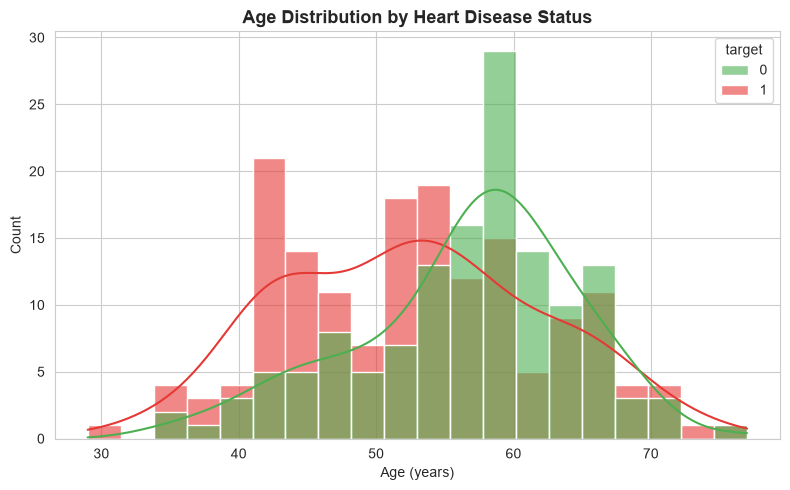

In [39]:
plt.figure(figsize=(8, 5))
sns.histplot(data=heart_clean, x="age", hue="target", bins=20, kde=True,
             palette=["#4CAF50", "#E53935"], alpha=0.6)
plt.title("Age Distribution by Heart Disease Status", fontsize=13, fontweight="bold")
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

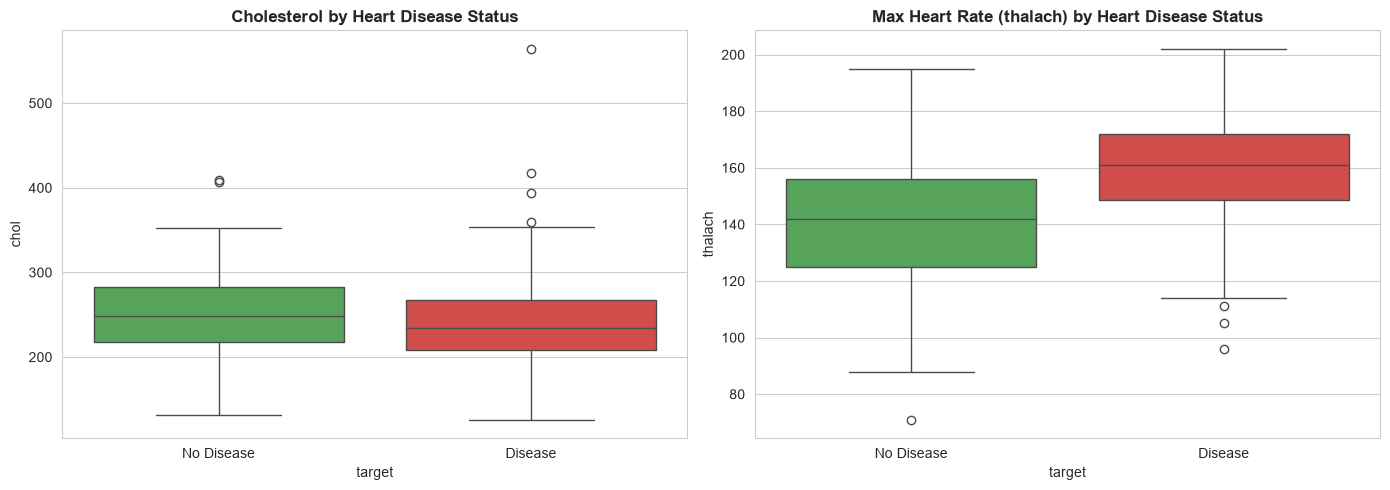

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=heart_clean, x="target", y="chol", palette=["#4CAF50", "#E53935"], ax=axes[0])
axes[0].set_title("Cholesterol by Heart Disease Status", fontweight="bold")
axes[0].set_xticklabels(["No Disease", "Disease"])

sns.boxplot(data=heart_clean, x="target", y="thalach", palette=["#4CAF50", "#E53935"], ax=axes[1])
axes[1].set_title("Max Heart Rate (thalach) by Heart Disease Status", fontweight="bold")
axes[1].set_xticklabels(["No Disease", "Disease"])

plt.tight_layout()
plt.show()

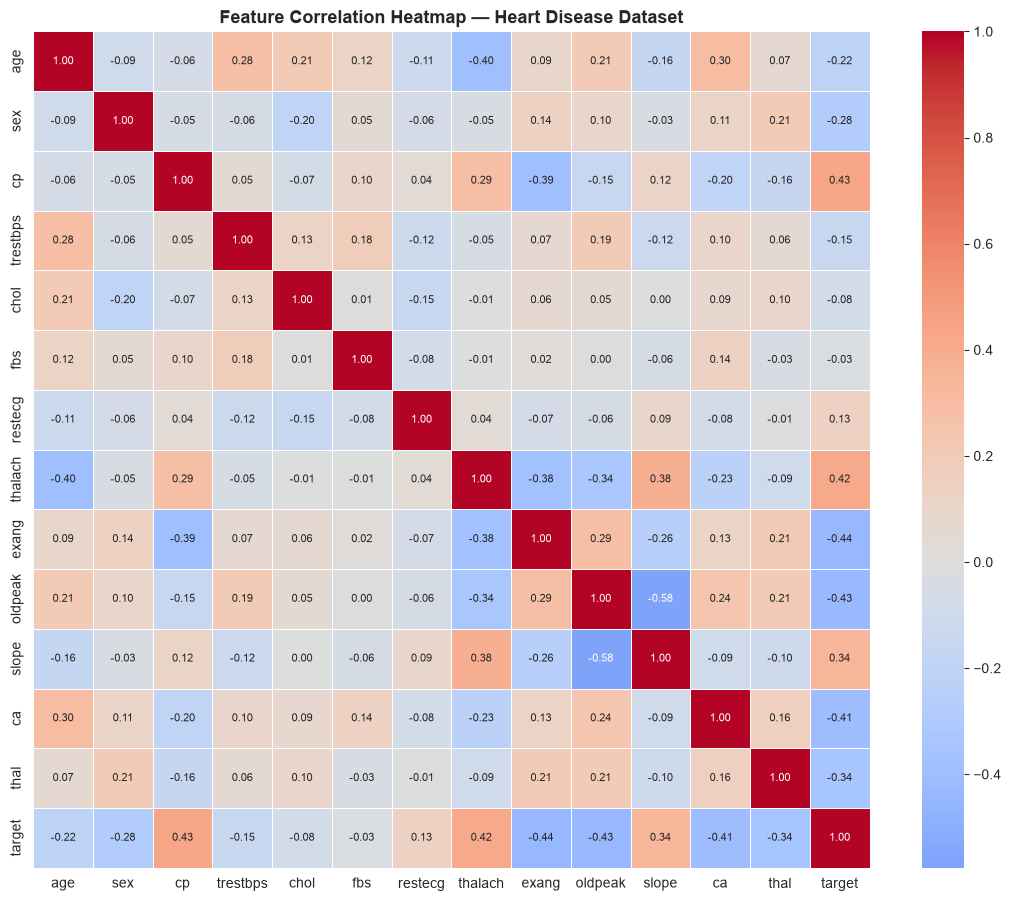

Correlation of each feature with target (sorted):
target      1.000
cp          0.432
thalach     0.420
slope       0.344
restecg     0.135
fbs        -0.027
chol       -0.081
trestbps   -0.146
age        -0.221
sex        -0.284
thal       -0.343
ca         -0.409
oldpeak    -0.429
exang      -0.436
Name: target, dtype: float64


In [41]:
plt.figure(figsize=(11, 9))
correlation_matrix = heart_clean.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True, annot_kws={"size": 8})
plt.title("Feature Correlation Heatmap — Heart Disease Dataset", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Correlation of each feature with target (sorted):")
print(correlation_matrix["target"].sort_values(ascending=False).round(3))

### EDA Summary — Heart Disease

- After deduplication, the dataset has 302 unique patient records.
- Class distribution and key feature relationships (age, cholesterol, max
  heart rate) were visualized against the target.
- The correlation output above identifies which features have the strongest
  linear relationship with heart disease presence — used as a baseline to
  compare against the trained model's own feature importance later.